In [1]:
import pickle as pkl
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

import pandas as pd
import seaborn as sns

import sys
sys.path.append('/scratch/gpfs/PRITYKIN/brendan/domino/python_modules')

from generic_plotting_functions import *
from plot_attributions_and_fimo import *

In [2]:
with open('/scratch/gpfs/PRITYKIN/brendan/domino/scripts/motif_synergy/new_synergy_rerun/final_rc_cooperativity_scores_rerun.pkl', 'rb') as f:
    motif_rc_cooperativity_scores = pkl.load(f)

coop_dict = dict()
for k, v in motif_rc_cooperativity_scores.items():
    key = k[0] + ', ' + k[1]
    coop_dict[key] = v
plot_df = pd.DataFrame(coop_dict).T

plot_df_T = plot_df.copy().T
top20_means = plot_df_T.apply(lambda col: col.nlargest(20).mean())
top20_means_df = pd.DataFrame([top20_means])

In [3]:
def df_to_matrix(df):
    s = df.iloc[0]
    s.index = s.index.str.split(", ", expand=True)
    matrix = s.rename_axis(['row', 'col']).unstack('col')
    matrix = matrix.T
    return matrix

synergy_df = df_to_matrix(top20_means_df)
synergy_df.columns = [c.replace('_fwd', '-FA').replace('_rev', '-RA') for c in synergy_df.copy().columns]
synergy_df.index = [c.replace('_fwd', '-FB').replace('_rev', '-RB') for c in synergy_df.copy().index]

/tmp/ipykernel_3738146/740570933.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_3738146/740570933.py:30: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


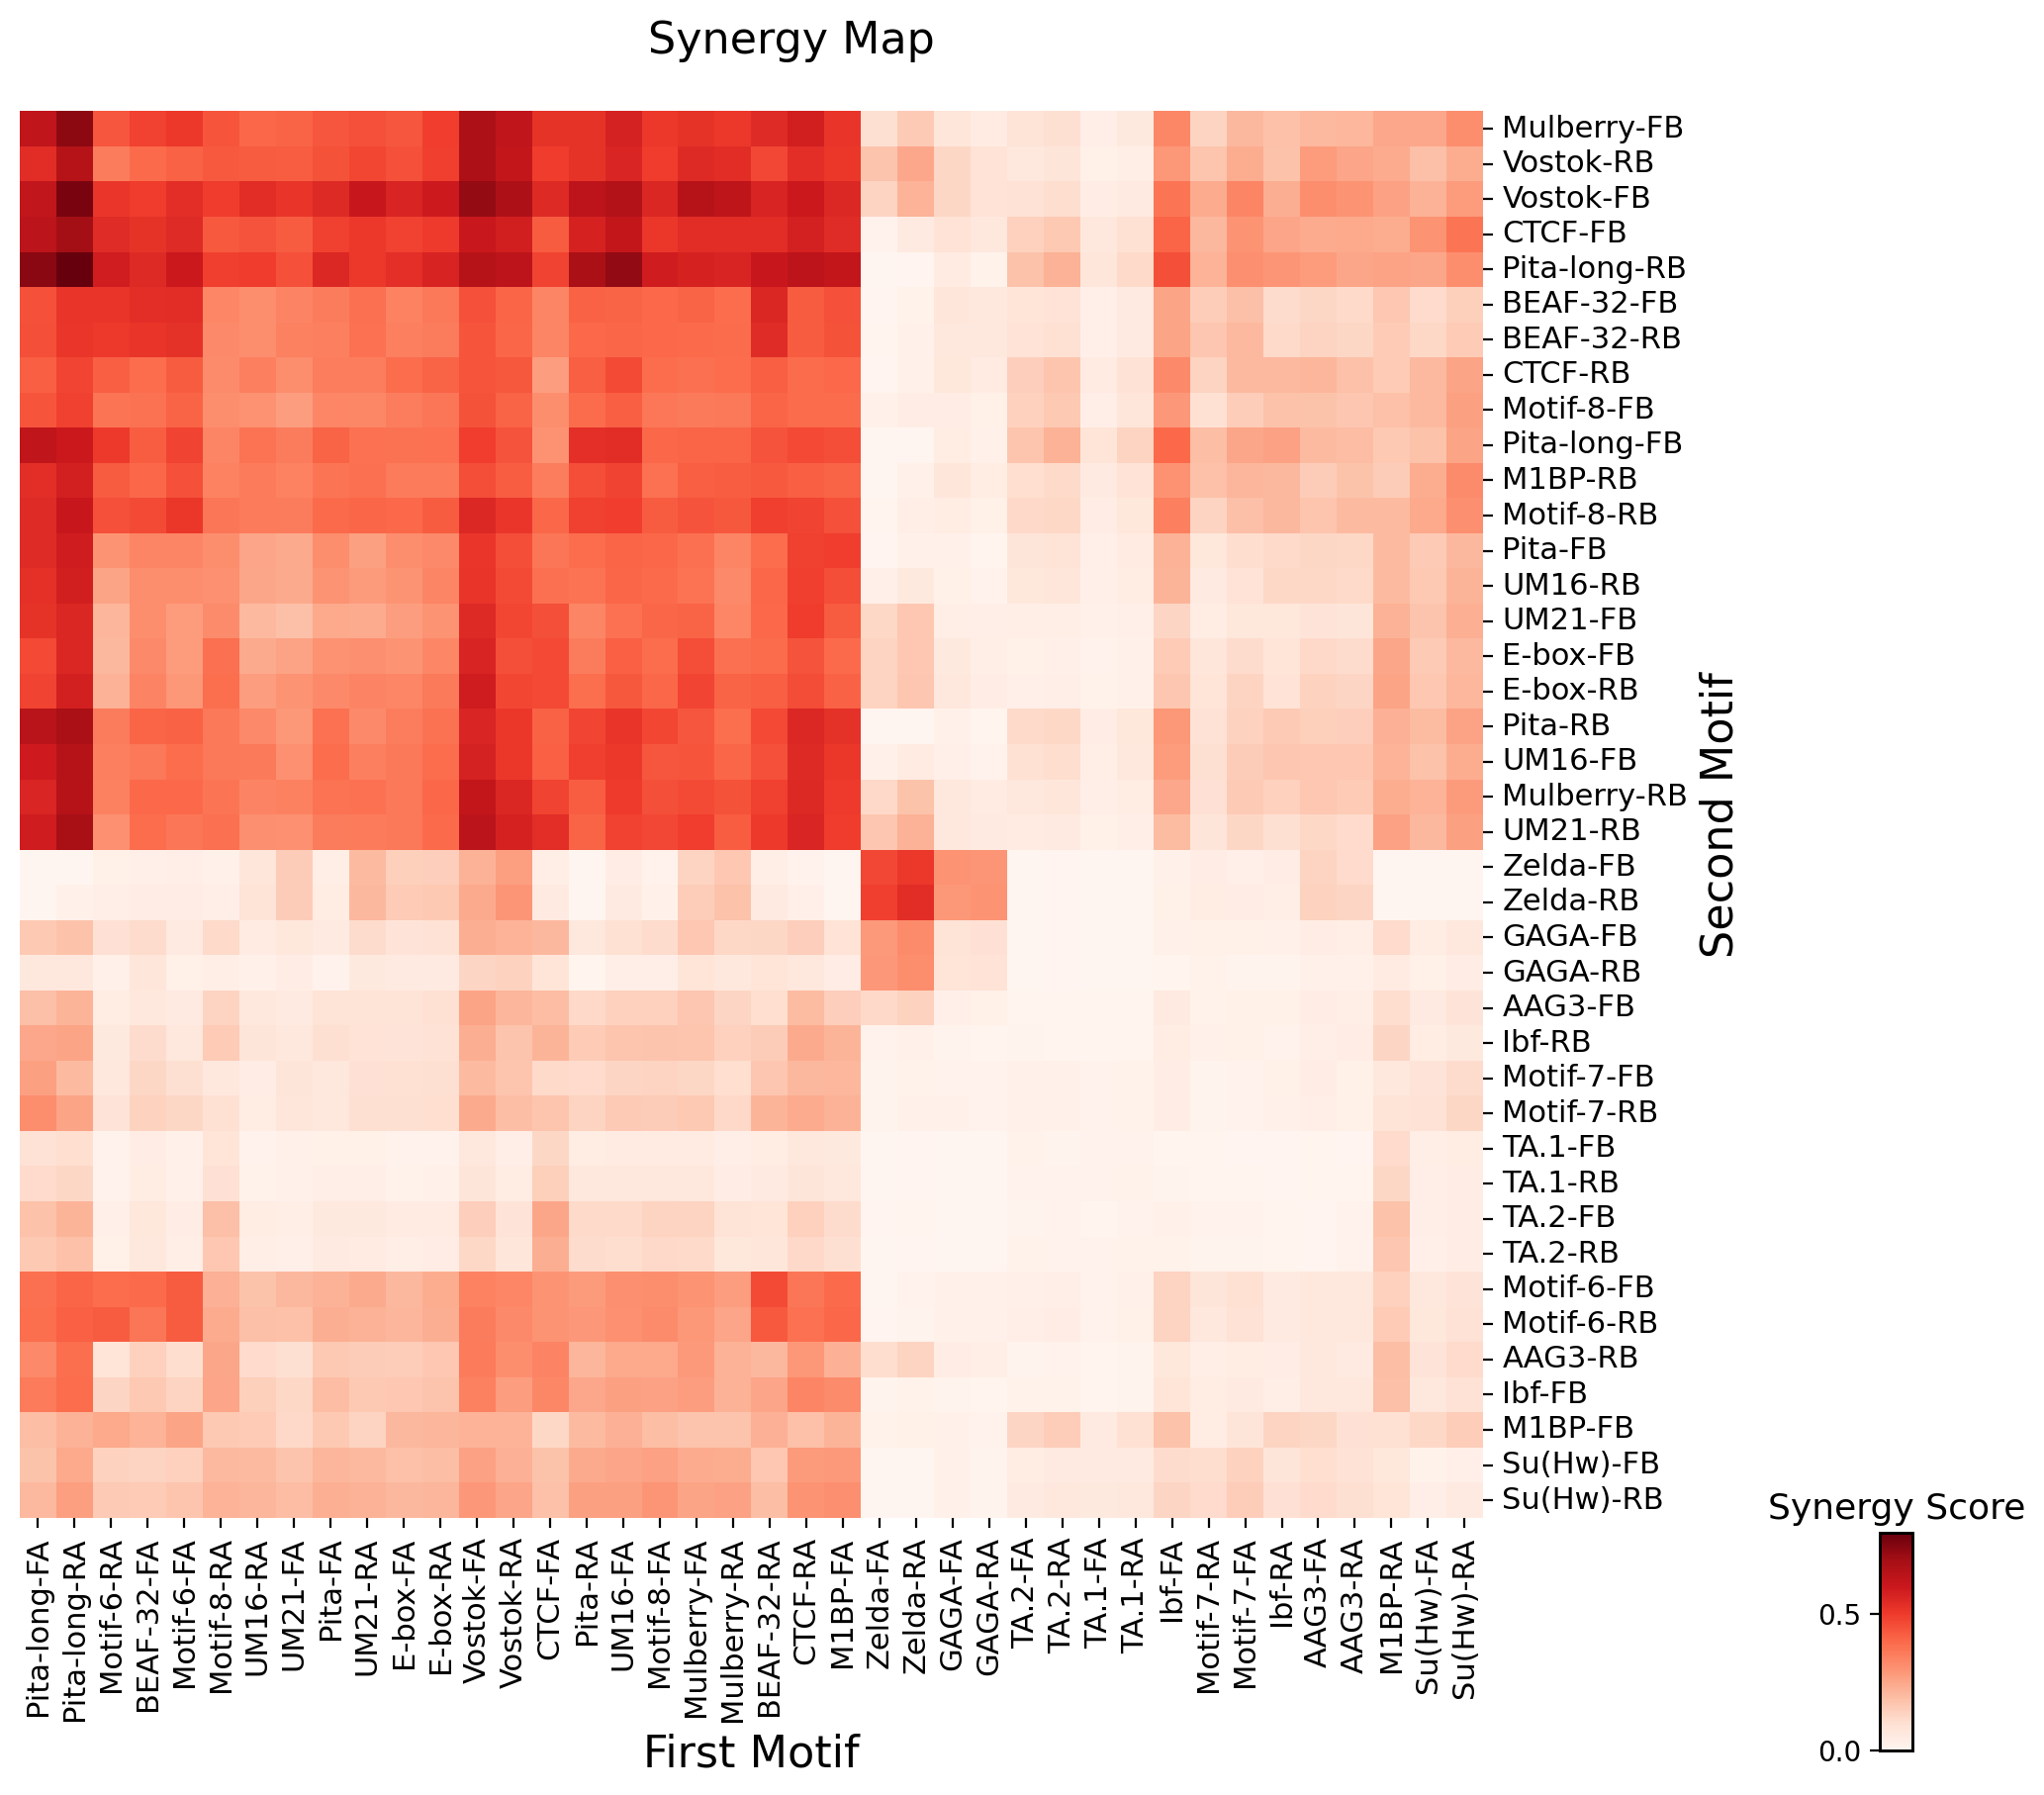

In [4]:
g = sns.clustermap(synergy_df, cmap="Reds", figsize=(11,11),
                   cbar_kws={"orientation": "horizontal"}, cbar_pos=None, vmin=0)

g.ax_heatmap.set_xticks([i + 0.5 for i in range(len(synergy_df.columns))])
col_order = g.dendrogram_col.reordered_ind
g.ax_heatmap.set_xticklabels(synergy_df.columns[col_order], ha='center', fontsize=11)

# Force and center y-tick labels
g.ax_heatmap.set_yticks([i + 0.5 for i in range(len(synergy_df.index))])
row_order = g.dendrogram_row.reordered_ind
g.ax_heatmap.set_yticklabels(synergy_df.index[row_order], rotation=0, va='center', fontsize=11)

g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)

cax = g.fig.add_axes([1.05, 0.025, 0.015, 0.1])  # [left, bottom, width, height]
cbar = plt.colorbar(g.ax_heatmap.collections[0], cax=cax, orientation="vertical")
# cbar.set_ticks([0, 0.8]) 
cax.yaxis.set_ticks_position('left')
for spine in cax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)  
    spine.set_edgecolor('black') # set the border color
cax.set_title("Synergy Score", fontsize=13, pad=5)


g.ax_heatmap.set_xlabel('First Motif', fontsize=16)
g.ax_heatmap.set_ylabel('Second Motif', fontsize=16)
g.fig.suptitle("Synergy Map", fontsize=16, y=0.82, x=0.55)  
plt.tight_layout()

# plt.savefig("plots/synergy_matrix.pdf", format="pdf", dpi=300, bbox_inches='tight')

plt.show()